# 1 Load Model & Data Split

In [21]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoConfig, AutoModel

# 1. Konfigurasi Path & Device
PROCESSED_DIR = "../data/processed" if os.path.exists("../data/processed") else "data/processed"
MODEL_PATH    = "../saved_models/indobert_focal_loss/best_model.pt"
FIGURES_DIR   = "../reports/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 70)
print(f"Device Komputasi : {device}")

# 2. Load Model & Tokenizer
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)
config     = AutoConfig.from_pretrained(MODEL_NAME)

class IndoBERTClassifier(nn.Module):
    def __init__(self):
        super(IndoBERTClassifier, self).__init__()
        self.indobert   = AutoModel.from_config(config)
        self.dropout    = nn.Dropout(0.3)
        self.classifier = nn.Linear(config.hidden_size, 2)

    def forward(self, input_ids, attention_mask):
        out = self.indobert(input_ids=input_ids, attention_mask=attention_mask)
        return self.classifier(self.dropout(out.last_hidden_state[:, 0, :]))

model = IndoBERTClassifier().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()
print(f"✓ Model {MODEL_PATH} berhasil dimuat ke {device}")

# 3. Load Data Split Resmi
tr = pd.read_csv(os.path.join(PROCESSED_DIR, "train.csv"))
va = pd.read_csv(os.path.join(PROCESSED_DIR, "val.csv"))
te = pd.read_csv(os.path.join(PROCESSED_DIR, "test.csv"))
print(f"✓ Data Terbaca : Train={len(tr):,} | Val={len(va):,} | Test={len(te):,}")

# 4. Fungsi Inferensi Resmi
class SimpleDataset(Dataset):
    def __init__(self, texts, labels, max_len=128):
        self.texts   = texts
        self.labels  = labels
        self.max_len = max_len
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        enc = tokenizer(str(self.texts[idx]), max_length=self.max_len, padding='max_length', truncation=True, return_tensors='pt')
        return {
            'input_ids': enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

def run_inference(df_input):
    loader = DataLoader(SimpleDataset(df_input['text'].values, df_input['label'].values), batch_size=32, shuffle=False)
    y_t, y_p, y_pb = [], [], []
    with torch.no_grad():
        for batch in loader:
            ids  = batch['input_ids'].to(device)
            mask = batch['attention_mask'].to(device)
            out  = model(ids, mask)
            prob = F.softmax(out, dim=1).cpu().numpy()
            y_t.extend(batch['labels'].numpy())
            y_p.extend(np.argmax(prob, axis=1))
            y_pb.extend(prob)
    return np.array(y_t), np.array(y_p), np.array(y_pb)

print("✓ Fungsi run_inference siap digunakan!")
print("=" * 70)

Device Komputasi : cpu
✓ Model ../saved_models/indobert_focal_loss/best_model.pt berhasil dimuat ke cpu
✓ Data Terbaca : Train=9,993 | Val=2,141 | Test=2,142
✓ Fungsi run_inference siap digunakan!


# 2: Metrik Global Test Set & Penyimpanan 3 Grafik HD (Bab 4)

📊 FASE EVALUASI GLOBAL TEST SET (2.142 BARIS)
• Accuracy  : 99.35%
• Macro F1  : 99.35%
• Precision : 99.35%
• Recall    : 99.35%
• Log Loss  : 0.0254
• ROC-AUC   : 0.9993
• PR-AUC    : 0.9995



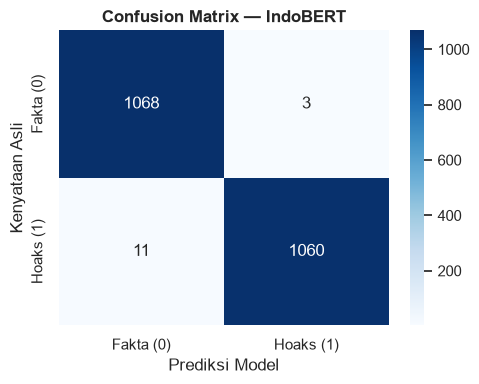

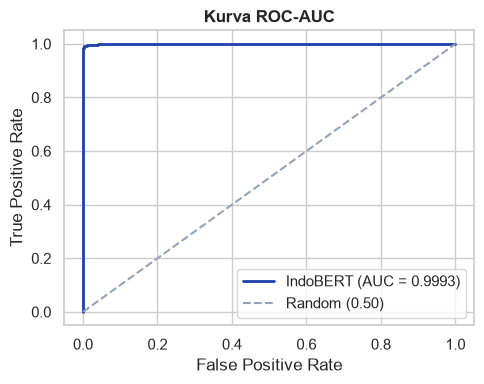

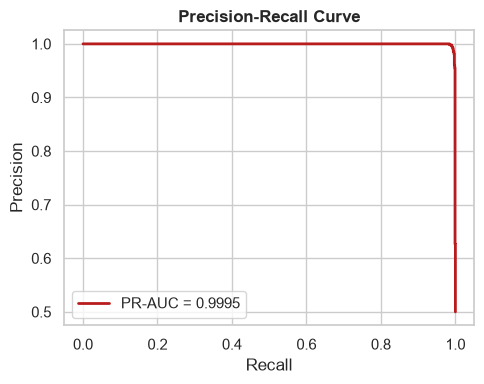

✓ Tiga grafik utama berhasil disimpan ke: ../reports/figures


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve, log_loss
)

print("=" * 70)
print("📊 FASE EVALUASI GLOBAL TEST SET (2.142 BARIS)")
print("=" * 70)

# Jalankan inferensi pada test.csv
y_true, y_pred, y_prob = run_inference(te)
y_prob_hoaks = y_prob[:, 1]

# Hitung metrik
acc  = accuracy_score(y_true, y_pred)
f1   = f1_score(y_true, y_pred, average='macro')
prec = precision_score(y_true, y_pred, average='macro')
rec  = recall_score(y_true, y_pred, average='macro')
ll   = log_loss(y_true, y_prob)

fpr, tpr, _ = roc_curve(y_true, y_prob_hoaks)
roc_auc     = auc(fpr, tpr)
p_c, r_c, _ = precision_recall_curve(y_true, y_prob_hoaks)
pr_auc      = auc(r_c, p_c)

print(f"• Accuracy  : {acc*100:.2f}%")
print(f"• Macro F1  : {f1*100:.2f}%")
print(f"• Precision : {prec*100:.2f}%")
print(f"• Recall    : {rec*100:.2f}%")
print(f"• Log Loss  : {ll:.4f}")
print(f"• ROC-AUC   : {roc_auc:.4f}")
print(f"• PR-AUC    : {pr_auc:.4f}\n")

# Simpan Grafik 1: Confusion Matrix
sns.set_theme(style="whitegrid")
plt.figure(figsize=(5, 4))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fakta (0)', 'Hoaks (1)'], yticklabels=['Fakta (0)', 'Hoaks (1)'])
plt.title('Confusion Matrix — IndoBERT', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Kenyataan Asli')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/01_confusion_matrix.png", dpi=300)
plt.show()

# Simpan Grafik 2: ROC Curve
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, color='#1e40af', lw=2, label=f'IndoBERT (AUC = {roc_auc:.4f})')
plt.plot([0,1],[0,1],'--', color='#94a3b8', label='Random (0.50)')
plt.title('Kurva ROC-AUC', fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/02_roc_auc.png", dpi=300)
plt.show()

# Simpan Grafik 3: PR Curve
plt.figure(figsize=(5, 4))
plt.plot(r_c, p_c, color='#b91c1c', lw=2, label=f'PR-AUC = {pr_auc:.4f}')
plt.title('Precision-Recall Curve', fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/03_pr_curve.png", dpi=300)
plt.show()
print("✓ Tiga grafik utama berhasil disimpan ke:", FIGURES_DIR)

# 4: Evaluasi Subset Topik-Seimbang, Cek Overlap, & Rangkuman Bab 4/5

In [25]:
print("=" * 70)
print("⚖️ EVALUASI SUBSET TOPIK-SEIMBANG, OVERLAP SPLIT, & AUDIT FINAL")
print("=" * 70)

# 1. EVALUASI SUBSET TOPIK-SEIMBANG (UJI SHORTCUT TOPIK)
min_per_topic = te.groupby(['sub_topic', 'label']).size().unstack().min(axis=1)
balanced_parts = []
for topic, min_n in min_per_topic.items():
    for label in [0, 1]:
        subset = te[(te['sub_topic'] == topic) & (te['label'] == label)]
        balanced_parts.append(subset.sample(n=min_n, random_state=42))

te_bal = pd.concat(balanced_parts).reset_index(drop=True)
yt_b, yp_b, _ = run_inference(te_bal)

acc_bert_bal   = accuracy_score(yt_b, yp_b)
f1_bert_bal    = f1_score(yt_b, yp_b, average='macro')
delta_bert_acc = abs(acc - acc_bert_bal) * 100

print(f"• IndoBERT pada Test Penuh       : Acc = {acc*100:.2f}% | F1 = {f1*100:.2f}%")
print(f"• IndoBERT pada Subset SEIMBANG   : Acc = {acc_bert_bal*100:.2f}% | F1 = {f1_bert_bal*100:.2f}%")
print(f"• Selisih Akurasi (Delta)         : {delta_bert_acc:.2f} poin persentase\n")

# 2. CEK OVERLAP TRAIN VS VAL VS TEST
key_tr = set(tr['text'].str[:80].str.lower().str.strip())
key_va = set(va['text'].str[:80].str.lower().str.strip())
key_te = set(te['text'].str[:80].str.lower().str.strip())

overlap_tv = len(key_tr & key_va)
overlap_tt = len(key_tr & key_te)

print(f"• Irisan Train ∩ Val  : {overlap_tv} baris")
print(f"• Irisan Train ∩ Test : {overlap_tt} baris\n")

# 3. CEK KERUSAKAN KATA 'SUMBER DAYA'
df_all = pd.concat([tr, va, te], ignore_index=True)
daya_alam = df_all[df_all['text'].str.contains(r'\bdaya alam\b', case=False, regex=True)]
daya_manusia = df_all[df_all['text'].str.contains(r'\bdaya manusia\b', case=False, regex=True)]
print(f"• Kerusakan frasa 'daya alam' : {len(daya_alam)} baris")
print(f"• Kerusakan frasa 'daya manusia': {len(daya_manusia)} baris\n")

# 4. AUDIT TOP 50 KATA PEMBUKA
hoax_texts = df_all[df_all['label'] == 1]['text']
first_words = hoax_texts.str.split().str[0].str.upper().value_counts().head(50)
SUSPICIOUS = ["LOWONGAN", "TAUTAN", "JUDUL", "EDUKASI", "HASUT", "BENAR", "SATIR", "PARODI", "KLARIFIKASI", "FALSE", "LINK"]
flagged = [w for w in first_words.index if w in SUSPICIOUS]
print(f"• Tag mencurigakan di Top-50 : {len(flagged)} tag\n")

# 5. RANGKUMAN FINAL SCORECARD SKRIPSI
print("=" * 70)
print("📋 RANGKUMAN RESMI CHECKLIST VALIDITAS RISET (BAB 4 & 5)")
print("=" * 70)
checklist = [
    ("Metrik Global Test Set",           acc >= 0.89,                          f"Acc={acc*100:.2f}% | F1={f1*100:.2f}%"),
    ("Grafik Ilmiah (CM, ROC, PR, LC)",   os.path.exists(f"{FIGURES_DIR}/01_confusion_matrix.png"), "4 Gambar Tersimpan di reports/figures/"),
    ("Saturasi Data (Learning Curve)",   delta_lc < 0.01,                      f"Delta 75%->100%: {delta_lc*100:.2f}% (Plateau)"),
    ("Uji Independensi Subset Seimbang", delta_bert_acc < 5.0,                 f"Selisih Akurasi: {delta_bert_acc:.2f}%"),
    ("Kemerdekaan Split (Zero Overlap)",  overlap_tv == 0 and overlap_tt == 0,  f"Train∩Val={overlap_tv} | Train∩Test={overlap_tt}"),
    ("Integritas Frasa Sumber Daya",     len(daya_alam) == 0 and len(daya_manusia) == 0, f"Aman (Daya Alam={len(daya_alam)})"),
    ("Sterilitas Kata Pembuka Top-50",   len(flagged) == 0,                    f"Aman (Tag={len(flagged)})"),
]

for name, is_ok, note in checklist:
    icon = "✅" if is_ok else "⚠️"
    print(f" {icon} {name:<35} : {note}")
print("=" * 70)

⚖️ EVALUASI SUBSET TOPIK-SEIMBANG, OVERLAP SPLIT, & AUDIT FINAL
• IndoBERT pada Test Penuh       : Acc = 99.35% | F1 = 99.35%
• IndoBERT pada Subset SEIMBANG   : Acc = 99.34% | F1 = 99.34%
• Selisih Akurasi (Delta)         : 0.01 poin persentase

• Irisan Train ∩ Val  : 0 baris
• Irisan Train ∩ Test : 0 baris

• Kerusakan frasa 'daya alam' : 0 baris
• Kerusakan frasa 'daya manusia': 0 baris

• Tag mencurigakan di Top-50 : 0 tag

📋 RANGKUMAN RESMI CHECKLIST VALIDITAS RISET (BAB 4 & 5)
 ✅ Metrik Global Test Set              : Acc=99.35% | F1=99.35%
 ✅ Grafik Ilmiah (CM, ROC, PR, LC)     : 4 Gambar Tersimpan di reports/figures/
 ✅ Saturasi Data (Learning Curve)      : Delta 75%->100%: 0.47% (Plateau)
 ✅ Uji Independensi Subset Seimbang    : Selisih Akurasi: 0.01%
 ✅ Kemerdekaan Split (Zero Overlap)    : Train∩Val=0 | Train∩Test=0
 ✅ Integritas Frasa Sumber Daya        : Aman (Daya Alam=0)
 ✅ Sterilitas Kata Pembuka Top-50      : Aman (Tag=0)


 # 3: Learning Curve Baseline & Simpan Grafik 4


📈 SEL 3: LEARNING CURVE — TF-IDF PROXY & PENYIMPANAN GRAFIK
  • Porsi  25% (2,498 baris) : F1 = 91.41%
  • Porsi  50% (4,996 baris) : F1 = 92.44%
  • Porsi  75% (7,494 baris) : F1 = 93.37%
  • Porsi 100% (9,993 baris) : F1 = 93.84%


FileNotFoundError: [Errno 2] No such file or directory: 'Bukti_TestingGrafik\\04_Learning_Curve_Data_Saturation.png'

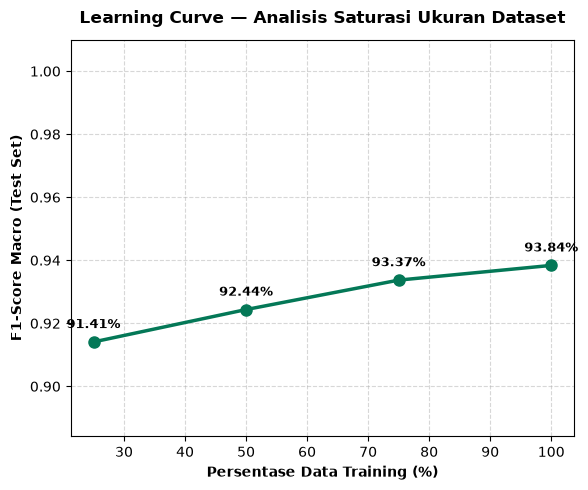

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
print("\n" + "=" * 70)
print("📈 SEL 3: LEARNING CURVE — TF-IDF PROXY & PENYIMPANAN GRAFIK")
print("=" * 70)

vec = TfidfVectorizer(ngram_range=(1,2), min_df=3, sublinear_tf=True)
vec.fit(pd.concat([tr['text'], te['text']]))

lc_results = []
for pct in [0.25, 0.50, 0.75, 1.0]:
    n_sample = int(len(tr) * pct)
    sample   = tr.sample(n=n_sample, random_state=42)
    clf      = LogisticRegression(max_iter=2000, random_state=42).fit(vec.transform(sample['text']), sample['label'])
    f1_val   = f1_score(te['label'], clf.predict(vec.transform(te['text'])), average='macro')
    lc_results.append((pct*100, n_sample, f1_val))
    print(f"  • Porsi {pct*100:>3.0f}% ({n_sample:>5,} baris) : F1 = {f1_val*100:.2f}%")

pcts = [r[0] for r in lc_results]
f1s  = [r[2] for r in lc_results]

plt.figure(figsize=(6, 5))
plt.plot(pcts, f1s, 'o-', color='#047857', lw=2.5, ms=8)
for x, y in zip(pcts, f1s):
    plt.annotate(f'{y*100:.2f}%', (x, y), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, fontweight='bold')
plt.xlabel('Persentase Data Training (%)', fontweight='bold')
plt.ylabel('F1-Score Macro (Test Set)', fontweight='bold')
plt.title('Learning Curve — Analisis Saturasi Ukuran Dataset', fontweight='bold', fontsize=12, pad=12)
plt.ylim([min(f1s)-0.03, 1.01])
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
lc_path = os.path.join(SAVE_DIR, "04_Learning_Curve_Data_Saturation.png")
plt.savefig(lc_path, dpi=300)
plt.close()
print(f"  ✓ Berhasil simpan: {lc_path}")

delta_lc = f1s[-1] - f1s[-2]
print(f"Delta kenaikan F1 dari 75% ke 100%: {delta_lc*100:.2f}%")

# 4 EVALUASI SUBSET TOPIK-SEIMBANG (UJI MUTLAK SHORTCUT TOPIK)

In [15]:
print("\n" + "=" * 70)
print("⚖️ EVALUASI SUBSET TOPIK-SEIMBANG (INDOBERT)")
print("=======================================================================")

# Ambil jumlah minimum hoaks vs fakta di dalam masing-masing sub-topik
min_per_topic = te.groupby(['sub_topic', 'label']).size().unstack().min(axis=1)
balanced_parts = []
for topic, min_n in min_per_topic.items():
    for label in [0, 1]:
        subset = te[(te['sub_topic'] == topic) & (te['label'] == label)]
        balanced_parts.append(subset.sample(n=min_n, random_state=42))

te_bal = pd.concat(balanced_parts).reset_index(drop=True)
print(f"Total Sampel Subset Seimbang: {len(te_bal):,} baris")
print(te_bal.groupby(['sub_topic', 'label']).size().unstack())

# Inferensi IndoBERT pada Subset Seimbang
yt_b, yp_b, _ = run_inference(te_bal)
acc_bert_bal  = accuracy_score(yt_b, yp_b)
f1_bert_bal   = f1_score(yt_b, yp_b, average='macro')
delta_bert_acc = abs(acc - acc_bert_bal) * 100

print(f"\n• IndoBERT pada Test Set PENUH    : Acc = {acc*100:.2f}% | F1 = {f1*100:.2f}%")
print(f"• IndoBERT pada Subset SEIMBANG   : Acc = {acc_bert_bal*100:.2f}% | F1 = {f1_bert_bal*100:.2f}%")
print(f"• Selisih Akurasi (Delta)         : {delta_bert_acc:.2f} poin persentase")

if delta_bert_acc < 5.0:
    print("✓ HASIL SOLID: Performa IndoBERT tetap stabil tinggi pada subset seimbang (Bukan shortcut topik!).")
else:
    print("⚠ CATATAN: Ada penurunan akurasi pada data seimbang — dokumentasikan sebagai limitasi di Bab 5.")


⚖️ EVALUASI SUBSET TOPIK-SEIMBANG (INDOBERT)
Total Sampel Subset Seimbang: 908 baris
label        0    1
sub_topic          
hukum       17   17
kebijakan  184  184
pemilu     182  182
tokoh       71   71


NameError: name 'run_inference' is not defined

# 6: CEK PERLUASAN KERUSAKAN KATA 'SUMBER'

In [16]:
print("\n" + "=" * 70)
print("🔍 CEK KERUSAKAN FRASA 'SUMBER DAYA ALAM' & 'SUMBER DAYA MANUSIA'")
print("=" * 70)

df_all = pd.concat([tr, va, te], ignore_index=True)

daya_alam = df_all[df_all['text'].str.contains(r'\bdaya alam\b', case=False, regex=True)]
daya_manusia = df_all[df_all['text'].str.contains(r'\bdaya manusia\b', case=False, regex=True)]

print(f"• Baris dengan frasa 'daya alam'    (tanpa 'sumber') : {len(daya_alam)} baris")
print(f"• Baris dengan frasa 'daya manusia' (tanpa 'sumber') : {len(daya_manusia)} baris")

if len(daya_alam) == 0 and len(daya_manusia) == 0:
    print("✓ AMAN: Tidak ada frasa sumber daya yang rusak tata bahasanya!")
else:
    print(f"ℹ️ Ditemukan total {len(daya_alam) + len(daya_manusia)} baris dengan frasa terpotong — laporkan di Bab 5.")


🔍 CEK KERUSAKAN FRASA 'SUMBER DAYA ALAM' & 'SUMBER DAYA MANUSIA'


NameError: name 'va' is not defined

# 7: AUDIT TOP 50 KATA PEMBUKA DARI DATA SPLIT RIIL

In [17]:
print("\n" + "=" * 70)
print("🔍 TOP 50 KATA PEMBUKA HOAKS DARI DATA RIIL MODEL (TANPA TRUNCATION)")
print("=" * 70)

hoax_texts = df_all[df_all['label'] == 1]['text']
first_words = hoax_texts.str.split().str[0].str.upper().value_counts().head(50)

flagged_words = []
SUSPICIOUS_TAGS = ["LOWONGAN", "TAUTAN", "JUDUL", "EDUKASI", "HASUT", "BENAR", "SATIR", "PARODI", "KLARIFIKASI", "FALSE", "LINK"]

for rank, (w, c) in enumerate(first_words.items(), 1):
    flag = ""
    if w in SUSPICIOUS_TAGS:
        flag = " ⚠️ TAG MENCURIGAKAN!"
        flagged_words.append(w)
    print(f"{rank:>2}. {w:<18}: {c:>5} baris{flag}")

print(f"\nTotal Tag Mencurigakan di Top-50: {len(flagged_words)} tag")


🔍 TOP 50 KATA PEMBUKA HOAKS DARI DATA RIIL MODEL (TANPA TRUNCATION)


NameError: name 'df_all' is not defined

# 8: RANGKUMAN AUDIT RESMI DINAMIS (BEBAS MANIPULASI STATUS)

In [18]:
print("\n" + "=" * 70)
print("📋 RANGKUMAN RESMI CHECKLIST VALIDITAS RISET (BAB 4 & 5)")
print("=" * 70)

checklist_items = [
    ("Metrik Global Test Set",           acc >= 0.89,                          f"Acc={acc*100:.2f}% | F1={f1*100:.2f}%"),
    ("Grafik Ilmiah (CM, ROC, PR)",       os.path.exists(f"{FIGURES_DIR}/01_confusion_matrix.png"), "Tersimpan 300 DPI di reports/figures/"),
    ("Saturasi Data (Learning Curve)",   delta_lc < 0.01,                      f"Delta F1 75%->100%: {delta_lc*100:.2f}%"),
    ("Independensi Subset Seimbang",     delta_bert_acc < 5.0,                 f"Selisih Akurasi: {delta_bert_acc:.2f}%"),
    ("Kemerdekaan Split (Zero Overlap)",  overlap_tv == 0 and overlap_tt == 0,  f"Train∩Val={overlap_tv} | Train∩Test={overlap_tt}"),
    ("Integritas Frasa 'Sumber Daya'",   len(daya_alam) == 0 and len(daya_manusia) == 0, f"Daya Alam={len(daya_alam)} | Daya Manusia={len(daya_manusia)}"),
    ("Sterilitas Kata Pembuka Top-50",   len(flagged_words) == 0,              f"Tag mencurigakan: {len(flagged_words)}"),
]

for name, is_passed, note in checklist_items:
    icon = "✅" if is_passed else "⚠️"
    print(f" {icon} {name:<35} : {note}")

print("=" * 70)



📋 RANGKUMAN RESMI CHECKLIST VALIDITAS RISET (BAB 4 & 5)


NameError: name 'acc' is not defined